In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", None)


In [4]:
sf24 = pd.read_csv('Crop_recommendationV2.csv')

print("SF24 dataset loaded successfully.")

SF24 dataset loaded successfully.


In [5]:
print("Rows:", sf24.shape[0])
print("Columns:", sf24.shape[1])
print("Shape:", sf24.shape)

Rows: 2200
Columns: 23
Shape: (2200, 23)


In [6]:
sf24.head()

,N,P,K,temperature,humidity,ph,rainfall,label,soil_moisture,soil_type,sunlight_exposure,wind_speed,co2_concentration,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,29.446064,2,8.677355,10.109875,435.611226,3.121395,4,11.743910,57.607308,188.194958,1,2.719614,3,95.649985,1.193293
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,12.851183,3,5.754288,12.048050,401.451860,2.142021,4,16.797101,74.736879,70.963629,1,4.714427,2,77.265694,1.752672
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,29.363913,2,9.875230,9.051349,357.417963,1.474974,1,12.654395,1.034478,191.976077,1,30.431736,2,18.192168,3.035541
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,26.207732,3,8.023685,7.963606,363.694306,8.393907,1,10.864360,24.091888,55.761388,3,10.861071,3,82.818720,1.273341
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,28.236236,2,8.120512,19.264133,410.356458,5.202285,3,13.852910,38.811481,185.259702,2,47.190777,3,25.466499,2.578671


In [7]:
sf24.tail()

,N,P,K,temperature,humidity,ph,rainfall,label,soil_moisture,soil_type,sunlight_exposure,wind_speed,co2_concentration,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee,10.697757,1,10.330875,19.192361,439.079069,4.720355,5,18.597260,87.431199,185.833381,3,31.415618,1,77.719639,4.111619
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee,12.203830,3,6.070558,10.603401,405.259540,4.141148,6,15.417979,36.958354,198.541021,2,18.797510,3,22.336839,4.190796
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee,28.989176,3,11.097182,13.842016,360.482605,1.599614,5,12.956675,79.678658,86.724381,2,38.805888,3,41.782729,2.447010
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee,13.642305,2,8.097337,16.537831,415.514314,8.934077,6,16.868131,31.007156,72.191421,2,8.395498,3,49.619791,4.119388
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee,23.911728,3,8.639742,14.481757,413.123716,6.401994,3,14.652123,3.574191,175.104241,3,26.784996,2,47.271267,2.758819


In [8]:
print("SF24 Columns:\n")

for i, column in enumerate(sf24.columns, start=1):
    print(f"{i}. {column}")

SF24 Columns:

1. N
2. P
3. K
4. temperature
5. humidity
6. ph
7. rainfall
8. label
9. soil_moisture
10. soil_type
11. sunlight_exposure
12. wind_speed
13. co2_concentration
14. organic_matter
15. irrigation_frequency
16. crop_density
17. pest_pressure
18. fertilizer_usage
19. growth_stage
20. urban_area_proximity
21. water_source_type
22. frost_risk
23. water_usage_efficiency


In [9]:
sf24.dtypes

N                           int64
P                           int64
K                           int64
temperature               float64
humidity                  float64
ph                        float64
rainfall                  float64
label                      object
soil_moisture             float64
soil_type                   int64
sunlight_exposure         float64
wind_speed                float64
co2_concentration         float64
organic_matter            float64
irrigation_frequency        int64
crop_density              float64
pest_pressure             float64
fertilizer_usage          float64
growth_stage                int64
urban_area_proximity      float64
water_source_type           int64
frost_risk                float64
water_usage_efficiency    float64
dtype: object

In [10]:
sf24.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       2200 non-null   int64  
 1   P                       2200 non-null   int64  
 2   K                       2200 non-null   int64  
 3   temperature             2200 non-null   float64
 4   humidity                2200 non-null   float64
 5   ph                      2200 non-null   float64
 6   rainfall                2200 non-null   float64
 7   label                   2200 non-null   object 
 8   soil_moisture           2200 non-null   float64
 9   soil_type               2200 non-null   int64  
 10  sunlight_exposure       2200 non-null   float64
 11  wind_speed              2200 non-null   float64
 12  co2_concentration       2200 non-null   float64
 13  organic_matter          2200 non-null   float64
 14  irrigation_frequency    2200 non-null   

In [11]:
sf24.select_dtypes(include=np.number).columns.tolist()

['N',
 'P',
 'K',
 'temperature',
 'humidity',
 'ph',
 'rainfall',
 'soil_moisture',
 'soil_type',
 'sunlight_exposure',
 'wind_speed',
 'co2_concentration',
 'organic_matter',
 'irrigation_frequency',
 'crop_density',
 'pest_pressure',
 'fertilizer_usage',
 'growth_stage',
 'urban_area_proximity',
 'water_source_type',
 'frost_risk',
 'water_usage_efficiency']

In [12]:
sf24.select_dtypes(include="object").columns.tolist()

['label']

In [13]:
sf24.select_dtypes(include="object").columns.tolist()

['label']

In [14]:
sf24.select_dtypes(include=np.number).columns.tolist()

['N',
 'P',
 'K',
 'temperature',
 'humidity',
 'ph',
 'rainfall',
 'soil_moisture',
 'soil_type',
 'sunlight_exposure',
 'wind_speed',
 'co2_concentration',
 'organic_matter',
 'irrigation_frequency',
 'crop_density',
 'pest_pressure',
 'fertilizer_usage',
 'growth_stage',
 'urban_area_proximity',
 'water_source_type',
 'frost_risk',
 'water_usage_efficiency']

In [15]:
missing_sf24 = pd.DataFrame({
    "Missing Count": sf24.isnull().sum(),
    "Missing Percentage": sf24.isnull().mean() * 100
})

missing_sf24 = missing_sf24.sort_values(
    by="Missing Count",
    ascending=False
)

missing_sf24

,Missing Count,Missing Percentage
N,0,0.0
co2_concentration,0,0.0
frost_risk,0,0.0
water_source_type,0,0.0
urban_area_proximity,0,0.0
growth_stage,0,0.0
fertilizer_usage,0,0.0
pest_pressure,0,0.0
crop_density,0,0.0
irrigation_frequency,0,0.0


In [16]:
print("Total missing values:", sf24.isnull().sum().sum())

Total missing values: 0


In [17]:
print("Number of duplicate rows:", sf24.duplicated().sum())

Number of duplicate rows: 0


In [18]:
duplicate_percentage = (
    sf24.duplicated().sum() / len(sf24)
) * 100

print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate percentage: 0.00%


In [19]:
unique_sf24 = pd.DataFrame({
    "Column": sf24.columns,
    "Unique Values": [sf24[col].nunique(dropna=False) for col in sf24.columns]
})

unique_sf24

,Column,Unique Values
0,N,137
1,P,117
2,K,73
3,temperature,2200
4,humidity,2200
5,ph,2200
6,rainfall,2200
7,label,22
8,soil_moisture,2200
9,soil_type,3


In [20]:
for column in sf24.select_dtypes(include="object").columns:
    print("\n" + "=" * 60)
    print("Column:", column)
    print("Number of unique values:", sf24[column].nunique())
    print("Values:")
    print(sf24[column].unique()[:30])


Column: label
Number of unique values: 22
Values:
['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']


In [21]:
sf24.describe()

,N,P,K,temperature,humidity,ph,rainfall,soil_moisture,soil_type,sunlight_exposure,wind_speed,co2_concentration,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655,20.151388,1.991364,8.570609,10.170939,399.647514,5.465652,3.515000,12.344959,49.850701,125.846403,1.999545,24.801013,2.003636,50.304701,2.990268
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389,5.793720,0.812263,1.999382,5.739038,28.447148,2.605294,1.697912,4.297494,28.886354,43.564527,0.818999,14.523975,0.812021,28.580352,1.139637
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267,10.024260,1.000000,5.000710,0.002870,350.001385,1.003338,1.000000,5.004341,0.038103,50.209990,1.000000,0.017756,1.000000,0.054911,1.002106
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686,15.179949,1.000000,6.904620,5.282754,375.250302,3.203903,2.000000,8.585734,24.379866,88.030737,1.000000,12.212594,1.000000,26.104674,2.051814
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624,20.088481,2.000000,8.609968,10.256241,399.691470,5.418049,4.000000,12.303616,49.982421,126.441536,2.000000,24.922548,2.000000,50.171934,2.968675
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508,25.255146,3.000000,10.220394,15.057313,424.121617,7.686417,5.000000,15.975567,74.681904,163.850536,3.000000,37.322761,3.000000,75.262676,3.968736
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117,29.997860,3.000000,11.991041,19.991294,449.984390,9.999990,6.000000,19.988474,99.983849,199.982166,3.000000,49.992046,3.000000,99.957274,4.997130


In [22]:
sf24.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
N,2200.0,NaN,NaN,NaN,50.551818,36.917334,0.0,21.0,37.0,84.25,140.0
P,2200.0,NaN,NaN,NaN,53.362727,32.985883,5.0,28.0,51.0,68.0,145.0
K,2200.0,NaN,NaN,NaN,48.149091,50.647931,5.0,20.0,32.0,49.0,205.0
temperature,2200.0,NaN,NaN,NaN,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,NaN,NaN,NaN,71.481779,22.263812,14.25804,60.261953,80.473146,89.948771,99.981876
ph,2200.0,NaN,NaN,NaN,6.46948,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,NaN,NaN,NaN,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117
label,2200,22,rice,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
soil_moisture,2200.0,NaN,NaN,NaN,20.151388,5.79372,10.02426,15.179949,20.088481,25.255146,29.99786
soil_type,2200.0,NaN,NaN,NaN,1.991364,0.812263,1.0,1.0,2.0,3.0,3.0


In [23]:
numerical_summary_sf24 = sf24.select_dtypes(include=np.number).describe().T

numerical_summary_sf24

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117
soil_moisture,2200.0,20.151388,5.793720,10.024260,15.179949,20.088481,25.255146,29.997860
soil_type,2200.0,1.991364,0.812263,1.000000,1.000000,2.000000,3.000000,3.000000
sunlight_exposure,2200.0,8.570609,1.999382,5.000710,6.904620,8.609968,10.220394,11.991041


In [24]:
categorical_columns_sf24 = sf24.select_dtypes(include="object").columns

for column in categorical_columns_sf24:
    print("\n" + "=" * 60)
    print(column)
    print(sf24[column].value_counts(dropna=False).head(20))


label
label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
Name: count, dtype: int64


In [25]:
numeric_sf24 = sf24.select_dtypes(include=np.number)

infinite_values_sf24 = np.isinf(numeric_sf24).sum()

print("Infinite values by column:")
print(infinite_values_sf24)

Infinite values by column:
N                         0
P                         0
K                         0
temperature               0
humidity                  0
ph                        0
rainfall                  0
soil_moisture             0
soil_type                 0
sunlight_exposure         0
wind_speed                0
co2_concentration         0
organic_matter            0
irrigation_frequency      0
crop_density              0
pest_pressure             0
fertilizer_usage          0
growth_stage              0
urban_area_proximity      0
water_source_type         0
frost_risk                0
water_usage_efficiency    0
dtype: int64


In [26]:
numerical_columns_sf24 = sf24.select_dtypes(
    include=np.number
).columns

outlier_summary_sf24 = []

for column in numerical_columns_sf24:

    Q1 = sf24[column].quantile(0.25)
    Q3 = sf24[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (sf24[column] < lower_bound) |
        (sf24[column] > upper_bound)
    ).sum()

    outlier_summary_sf24.append([
        column,
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        outliers,
        (outliers / len(sf24)) * 100
    ])

outlier_summary_sf24 = pd.DataFrame(
    outlier_summary_sf24,
    columns=[
        "Column",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Potential Outliers",
        "Outlier Percentage"
    ]
)

outlier_summary_sf24

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
0,N,21.000000,84.250000,63.250000,-73.875000,179.125000,0,0.000000
1,P,28.000000,68.000000,40.000000,-32.000000,128.000000,138,6.272727
2,K,20.000000,49.000000,29.000000,-23.500000,92.500000,200,9.090909
3,temperature,22.769375,28.561654,5.792279,14.080956,37.250073,86,3.909091
4,humidity,60.261953,89.948771,29.686818,15.731726,134.478998,30,1.363636
5,ph,5.971693,6.923643,0.951950,4.543768,8.351567,57,2.590909
6,rainfall,64.551686,124.267508,59.715822,-25.022047,213.841241,100,4.545455
7,soil_moisture,15.179949,25.255146,10.075197,0.067154,40.367941,0,0.000000
8,soil_type,1.000000,3.000000,2.000000,-2.000000,6.000000,0,0.000000
9,sunlight_exposure,6.904620,10.220394,3.315773,1.930960,15.194054,0,0.000000


In [27]:
correlation_sf24 = sf24.select_dtypes(
    include=np.number
).corr()

correlation_sf24

,N,P,K,temperature,humidity,ph,rainfall,soil_moisture,soil_type,sunlight_exposure,wind_speed,co2_concentration,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
N,1.000000,-0.231460,-0.140512,0.026504,0.190688,0.096683,0.059020,-0.030749,0.021026,0.005456,0.068319,-0.007783,-0.000213,-0.005733,-0.012270,-0.019974,-0.023336,0.009785,-0.023980,0.020837,-0.021273,0.005164
P,-0.231460,1.000000,0.736232,-0.127541,-0.118734,-0.138019,-0.063839,0.017027,-0.000833,0.004664,-0.014726,-0.016216,-0.012194,0.012399,-0.042635,0.000187,-0.008490,-0.022348,0.044838,-0.009455,0.030244,0.009272
K,-0.140512,0.736232,1.000000,-0.160387,0.190859,-0.169503,-0.053461,0.008116,0.023587,0.004542,-0.019230,-0.026238,-0.024260,0.001386,-0.035940,0.011401,0.016329,-0.017419,0.034753,0.017159,0.025110,-0.000372
temperature,0.026504,-0.127541,-0.160387,1.000000,0.205320,-0.017795,-0.030084,-0.009842,-0.015571,0.001200,0.004092,-0.000539,0.015925,-0.031864,0.026098,-0.007207,0.015709,-0.002026,-0.001946,0.031165,-0.007591,0.036147
humidity,0.190688,-0.118734,0.190859,0.205320,1.000000,-0.008483,0.094423,0.010933,-0.012640,0.035394,0.018131,-0.013654,-0.012039,-0.016798,-0.032880,0.032015,0.033408,-0.009744,-0.041271,0.033118,-0.024591,-0.043027
ph,0.096683,-0.138019,-0.169503,-0.017795,-0.008483,1.000000,-0.109069,-0.023978,-0.020061,-0.008046,0.015065,0.002800,-0.010069,0.028987,0.002701,0.009845,-0.019893,-0.003723,0.043606,0.036664,-0.003499,-0.030026
rainfall,0.059020,-0.063839,-0.053461,-0.030084,0.094423,-0.109069,1.000000,-0.048593,0.012959,0.016778,0.038363,-0.009021,0.005035,0.002745,-0.005506,-0.031953,-0.011299,-0.035767,-0.022371,-0.001614,0.004942,-0.010738
soil_moisture,-0.030749,0.017027,0.008116,-0.009842,0.010933,-0.023978,-0.048593,1.000000,0.001269,0.006502,-0.008458,0.006661,0.023771,-0.044011,0.005281,0.010169,-0.000946,0.002546,0.000720,-0.015919,0.012678,0.005135
soil_type,0.021026,-0.000833,0.023587,-0.015571,-0.012640,-0.020061,0.012959,0.001269,1.000000,-0.006840,-0.024807,0.024108,-0.004594,0.026638,0.029293,-0.012971,-0.006542,0.024603,-0.008871,-0.019257,-0.034281,-0.001946
sunlight_exposure,0.005456,0.004664,0.004542,0.001200,0.035394,-0.008046,0.016778,0.006502,-0.006840,1.000000,-0.052757,0.009335,0.002313,0.004463,0.028616,0.016590,0.015251,0.042288,-0.003850,-0.017433,-0.012445,0.012438


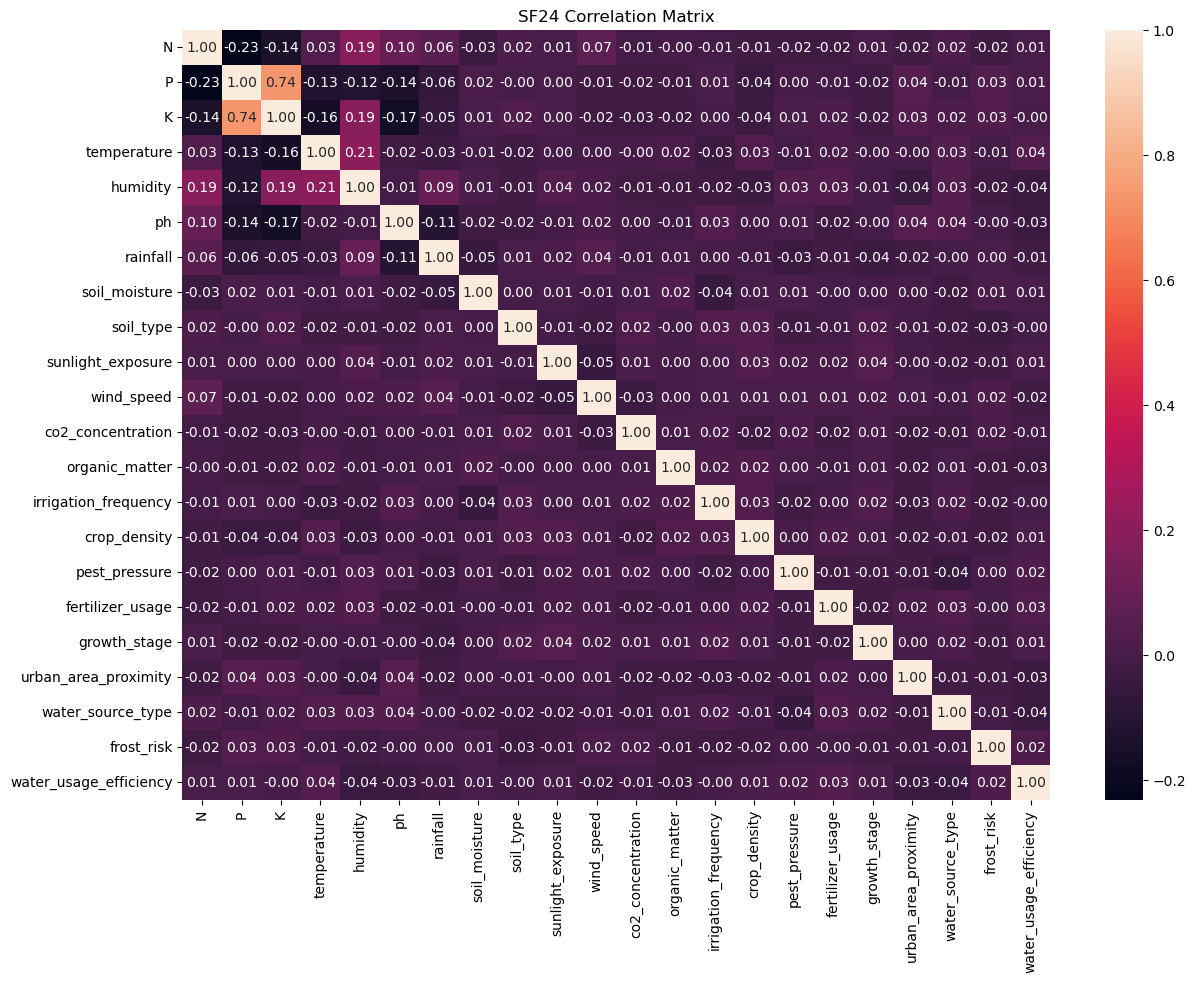

In [29]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_sf24,
    annot=True,
    fmt=".2f"
)

plt.title("SF24 Correlation Matrix")
plt.show()

In [30]:
sf24_summary = pd.DataFrame({
    "Property": [
        "Number of Rows",
        "Number of Columns",
        "Numerical Columns",
        "Categorical Columns",
        "Total Missing Values",
        "Duplicate Rows",
        "Infinite Values"
    ],
    "Value": [
        sf24.shape[0],
        sf24.shape[1],
        len(sf24.select_dtypes(include=np.number).columns),
        len(sf24.select_dtypes(include="object").columns),
        sf24.isnull().sum().sum(),
        sf24.duplicated().sum(),
        np.isinf(sf24.select_dtypes(include=np.number)).sum().sum()
    ]
})

sf24_summary

,Property,Value
0,Number of Rows,2200
1,Number of Columns,23
2,Numerical Columns,22
3,Categorical Columns,1
4,Total Missing Values,0
5,Duplicate Rows,0
6,Infinite Values,0


In [31]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print("AgriYield train and test loaded successfully.")

AgriYield train and test loaded successfully.


In [32]:
print("TRAIN DATASET")
print("Rows:", train.shape[0])
print("Columns:", train.shape[1])
print("Shape:", train.shape)

TRAIN DATASET
Rows: 10000
Columns: 9
Shape: (10000, 9)


In [33]:
print("\nTEST DATASET")
print("Rows:", test.shape[0])
print("Columns:", test.shape[1])
print("Shape:", test.shape)


TEST DATASET
Rows: 2000
Columns: 8
Shape: (2000, 8)


In [34]:
train.head()

,field_id,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi,yield
0,F00001,6.25,2.66,41.6,25.2,70,110.2,0.46,4105.8
1,F00002,6.70,3.66,40.2,26.9,78,126.3,0.59,4247.8
2,F00003,7.21,3.45,40.0,27.6,66,109.4,0.64,4021.8
3,F00004,5.73,2.48,56.9,29.6,79,155.3,0.62,4326.8
4,F00005,6.88,3.61,30.6,25.0,80,172.6,0.62,3708.0


In [35]:
test.head()

,field_id,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi
0,T00001,6.25,2.15,47.2,27.9,82,176.5,0.60
1,T00002,7.40,2.12,54.2,25.0,74,167.5,0.50
2,T00003,6.96,3.77,52.8,29.2,75,155.1,0.43
3,T00004,6.70,2.12,34.6,27.7,81,123.6,0.45
4,T00005,5.81,2.18,34.5,24.9,84,173.1,0.64


In [36]:
print("TRAIN COLUMNS\n")

for i, column in enumerate(train.columns, start=1):
    print(f"{i}. {column}")

TRAIN COLUMNS

1. field_id
2. soil_ph
3. organic_matter
4. sand_pct
5. temperature
6. humidity
7. rainfall
8. ndvi
9. yield


In [37]:
train_columns = set(train.columns)
test_columns = set(test.columns)

print("Columns only in TRAIN:")
print(train_columns - test_columns)

print("\nColumns only in TEST:")
print(test_columns - train_columns)

Columns only in TRAIN:
{'yield'}

Columns only in TEST:
set()


In [38]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   field_id        10000 non-null  object 
 1   soil_ph         10000 non-null  float64
 2   organic_matter  10000 non-null  float64
 3   sand_pct        10000 non-null  float64
 4   temperature     10000 non-null  float64
 5   humidity        10000 non-null  int64  
 6   rainfall        10000 non-null  float64
 7   ndvi            10000 non-null  float64
 8   yield           10000 non-null  float64
dtypes: float64(7), int64(1), object(1)
memory usage: 703.3+ KB


In [39]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   field_id        2000 non-null   object 
 1   soil_ph         2000 non-null   float64
 2   organic_matter  2000 non-null   float64
 3   sand_pct        2000 non-null   float64
 4   temperature     2000 non-null   float64
 5   humidity        2000 non-null   int64  
 6   rainfall        2000 non-null   float64
 7   ndvi            2000 non-null   float64
dtypes: float64(6), int64(1), object(1)
memory usage: 125.1+ KB


In [40]:
missing_train = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": train.isnull().mean() * 100
})

missing_train.sort_values(
    by="Missing Count",
    ascending=False
)

,Missing Count,Missing Percentage
field_id,0,0.0
soil_ph,0,0.0
organic_matter,0,0.0
sand_pct,0,0.0
temperature,0,0.0
humidity,0,0.0
rainfall,0,0.0
ndvi,0,0.0
yield,0,0.0


In [41]:
missing_train = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": train.isnull().mean() * 100
})

missing_train.sort_values(
    by="Missing Count",
    ascending=False
)

,Missing Count,Missing Percentage
field_id,0,0.0
soil_ph,0,0.0
organic_matter,0,0.0
sand_pct,0,0.0
temperature,0,0.0
humidity,0,0.0
rainfall,0,0.0
ndvi,0,0.0
yield,0,0.0


In [42]:
print("Train missing values:", train.isnull().sum().sum())
print("Test missing values:", test.isnull().sum().sum())

Train missing values: 0
Test missing values: 0


In [43]:
print("Train duplicates:", train.duplicated().sum())
print("Test duplicates:", test.duplicated().sum())

Train duplicates: 0
Test duplicates: 0


In [44]:
unique_train = pd.DataFrame({
    "Column": train.columns,
    "Unique Values": [
        train[col].nunique(dropna=False)
        for col in train.columns
    ]
})

unique_train

,Column,Unique Values
0,field_id,10000
1,soil_ph,201
2,organic_matter,251
3,sand_pct,301
4,temperature,61
5,humidity,20
6,rainfall,801
7,ndvi,36
8,yield,7276


In [45]:
unique_test = pd.DataFrame({
    "Column": test.columns,
    "Unique Values": [
        test[col].nunique(dropna=False)
        for col in test.columns
    ]
})

unique_test

,Column,Unique Values
0,field_id,2000
1,soil_ph,200
2,organic_matter,250
3,sand_pct,301
4,temperature,61
5,humidity,20
6,rainfall,739
7,ndvi,36


In [46]:
train.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
field_id,10000,10000,F00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
soil_ph,10000.0,NaN,NaN,NaN,6.508556,0.579959,5.5,6.0,6.51,7.01,7.5
organic_matter,10000.0,NaN,NaN,NaN,2.748447,0.717645,1.5,2.13,2.75,3.36,4.0
sand_pct,10000.0,NaN,NaN,NaN,44.95785,8.65291,30.0,37.5,45.0,52.4,60.0
temperature,10000.0,NaN,NaN,NaN,26.99392,1.736847,24.0,25.5,27.0,28.5,30.0
humidity,10000.0,NaN,NaN,NaN,74.5234,5.775101,65.0,70.0,75.0,80.0,84.0
rainfall,10000.0,NaN,NaN,NaN,140.03385,23.026794,100.0,120.2,140.1,160.2,180.0
ndvi,10000.0,NaN,NaN,NaN,0.574883,0.100168,0.4,0.49,0.57,0.66,0.75
yield,10000.0,NaN,NaN,NaN,4251.9764,436.533109,3500.2,3868.05,4257.15,4638.325,5000.0


In [47]:
test.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
field_id,2000,2000,T00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
soil_ph,2000.0,NaN,NaN,NaN,6.497095,0.584481,5.51,5.98,6.51,7.0,7.5
organic_matter,2000.0,NaN,NaN,NaN,2.741,0.721443,1.5,2.13,2.73,3.37,4.0
sand_pct,2000.0,NaN,NaN,NaN,44.8897,8.639153,30.0,37.4,44.75,52.2,60.0
temperature,2000.0,NaN,NaN,NaN,26.9264,1.724987,24.0,25.4,26.9,28.4,30.0
humidity,2000.0,NaN,NaN,NaN,74.6715,5.681085,65.0,70.0,75.0,80.0,84.0
rainfall,2000.0,NaN,NaN,NaN,139.9246,22.906476,100.0,120.975,139.6,159.4,180.0
ndvi,2000.0,NaN,NaN,NaN,0.5776,0.101077,0.4,0.49,0.58,0.66,0.75


In [48]:
train_numerical = train.select_dtypes(
    include=np.number
).columns.tolist()

train_categorical = train.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical columns:")
print(train_numerical)

print("\nCategorical columns:")
print(train_categorical)

Numerical columns:
['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi', 'yield']

Categorical columns:
['field_id']


In [49]:
test_numerical = test.select_dtypes(
    include=np.number
).columns.tolist()

test_categorical = test.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical columns:")
print(test_numerical)

print("\nCategorical columns:")
print(test_categorical)

Numerical columns:
['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi']

Categorical columns:
['field_id']


In [50]:
print(
    "Train infinite values:",
    np.isinf(train.select_dtypes(include=np.number)).sum().sum()
)

print(
    "Test infinite values:",
    np.isinf(test.select_dtypes(include=np.number)).sum().sum()
)

Train infinite values: 0
Test infinite values: 0


In [51]:
numerical_columns_train = train.select_dtypes(
    include=np.number
).columns

outlier_summary_train = []

for column in numerical_columns_train:

    Q1 = train[column].quantile(0.25)
    Q3 = train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (train[column] < lower_bound) |
        (train[column] > upper_bound)
    ).sum()

    outlier_summary_train.append([
        column,
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        outliers,
        (outliers / len(train)) * 100
    ])

outlier_summary_train = pd.DataFrame(
    outlier_summary_train,
    columns=[
        "Column",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Potential Outliers",
        "Outlier Percentage"
    ]
)

outlier_summary_train

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
0,soil_ph,6.00,7.010,1.010,4.4850,8.5250,0,0.0
1,organic_matter,2.13,3.360,1.230,0.2850,5.2050,0,0.0
2,sand_pct,37.50,52.400,14.900,15.1500,74.7500,0,0.0
3,temperature,25.50,28.500,3.000,21.0000,33.0000,0,0.0
4,humidity,70.00,80.000,10.000,55.0000,95.0000,0,0.0
5,rainfall,120.20,160.200,40.000,60.2000,220.2000,0,0.0
6,ndvi,0.49,0.660,0.170,0.2350,0.9150,0,0.0
7,yield,3868.05,4638.325,770.275,2712.6375,5793.7375,0,0.0


In [52]:
if "yield" in train.columns:

    print("Yield target found.")

    print("\nTarget statistics:")
    print(train["yield"].describe())

    print("\nMissing target values:")
    print(train["yield"].isnull().sum())

Yield target found.

Target statistics:
count    10000.000000
mean      4251.976400
std        436.533109
min       3500.200000
25%       3868.050000
50%       4257.150000
75%       4638.325000
max       5000.000000
Name: yield, dtype: float64

Missing target values:
0


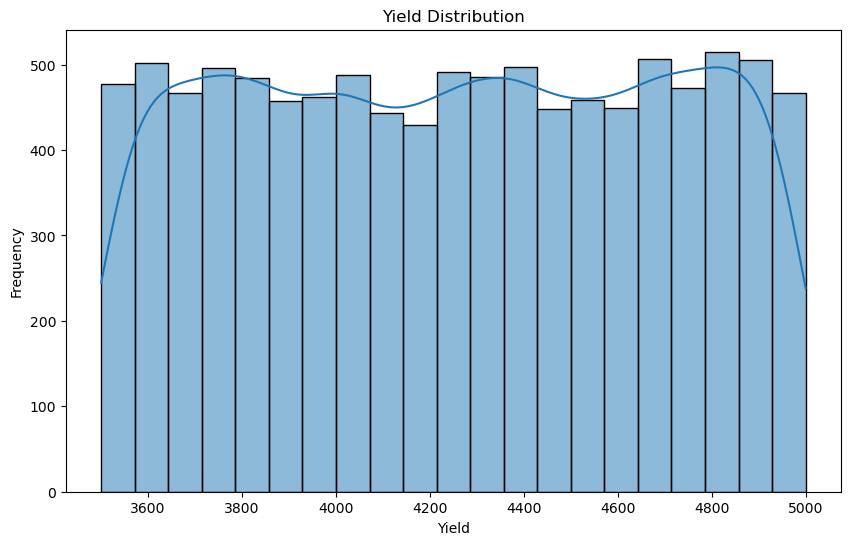

In [53]:
if "yield" in train.columns:

    plt.figure(figsize=(10, 6))

    sns.histplot(
        train["yield"],
        kde=True
    )

    plt.title("Yield Distribution")
    plt.xlabel("Yield")
    plt.ylabel("Frequency")

    plt.show()

In [54]:
correlation_train = train.select_dtypes(
    include=np.number
).corr()

correlation_train

,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi,yield
soil_ph,1.000000,-0.016595,-0.024560,-0.005485,-0.006664,-0.005365,-0.009469,0.007098
organic_matter,-0.016595,1.000000,0.000227,0.001544,-0.012198,0.007677,-0.007599,0.002207
sand_pct,-0.024560,0.000227,1.000000,0.008607,-0.004474,0.023181,-0.011729,-0.003933
temperature,-0.005485,0.001544,0.008607,1.000000,-0.013643,-0.015184,-0.009789,-0.014943
humidity,-0.006664,-0.012198,-0.004474,-0.013643,1.000000,0.003410,0.016542,0.001252
rainfall,-0.005365,0.007677,0.023181,-0.015184,0.003410,1.000000,-0.027723,0.016959
ndvi,-0.009469,-0.007599,-0.011729,-0.009789,0.016542,-0.027723,1.000000,-0.001619
yield,0.007098,0.002207,-0.003933,-0.014943,0.001252,0.016959,-0.001619,1.000000


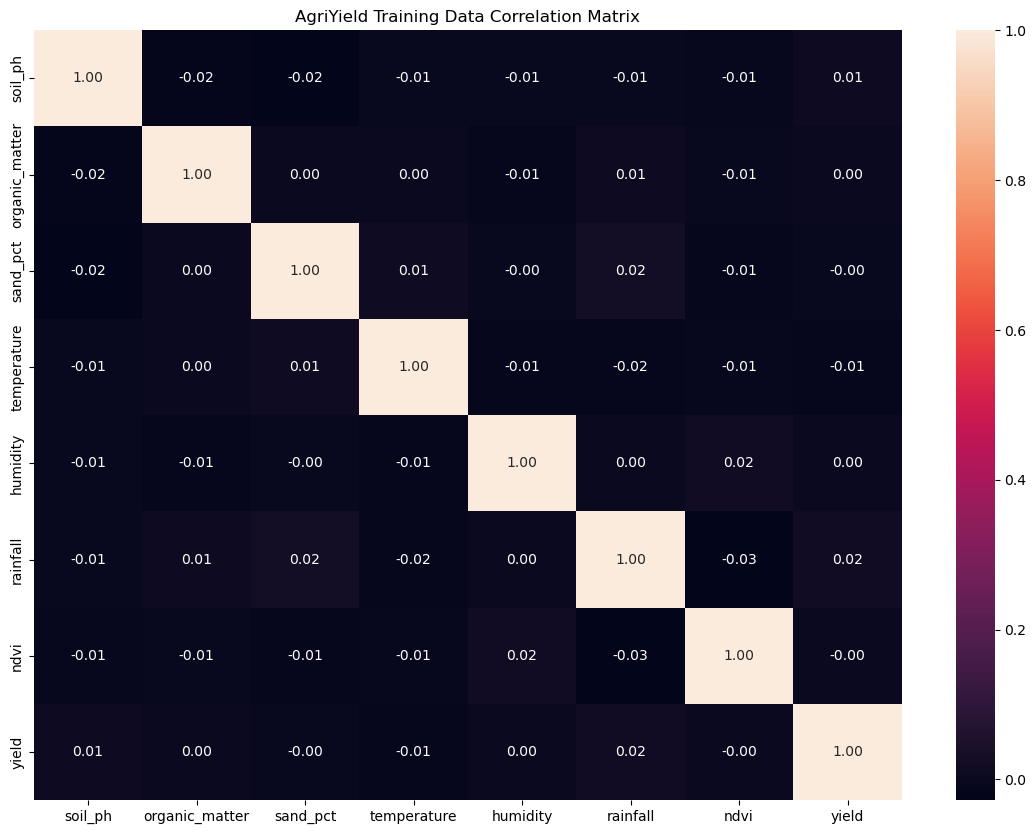

In [55]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_train,
    annot=True,
    fmt=".2f"
)

plt.title("AgriYield Training Data Correlation Matrix")

plt.show()

In [56]:
dataset_summary = pd.DataFrame({
    "Dataset": [
        "SF24",
        "AgriYield Train",
        "AgriYield Test"
    ],
    "Rows": [
        sf24.shape[0],
        train.shape[0],
        test.shape[0]
    ],
    "Columns": [
        sf24.shape[1],
        train.shape[1],
        test.shape[1]
    ],
    "Numerical Columns": [
        len(sf24.select_dtypes(include=np.number).columns),
        len(train.select_dtypes(include=np.number).columns),
        len(test.select_dtypes(include=np.number).columns)
    ],
    "Categorical Columns": [
        len(sf24.select_dtypes(include="object").columns),
        len(train.select_dtypes(include="object").columns),
        len(test.select_dtypes(include="object").columns)
    ],
    "Missing Values": [
        sf24.isnull().sum().sum(),
        train.isnull().sum().sum(),
        test.isnull().sum().sum()
    ],
    "Duplicate Rows": [
        sf24.duplicated().sum(),
        train.duplicated().sum(),
        test.duplicated().sum()
    ]
})

dataset_summary

,Dataset,Rows,Columns,Numerical Columns,Categorical Columns,Missing Values,Duplicate Rows
0,SF24,2200,23,22,1,0,0
1,AgriYield Train,10000,9,8,1,0,0
2,AgriYield Test,2000,8,7,1,0,0


In [61]:
import pandas as pd
import sqlite3
import os

In [62]:
project_path = r"C:\Users\ADMIN\smart agricultural analytics"

crop_df = pd.read_csv(
    os.path.join(project_path, "Crop_recommendationV2.csv")
)

train_df = pd.read_csv(
    os.path.join(project_path, "train.csv")
)

test_df = pd.read_csv(
    os.path.join(project_path, "test.csv")
)

print("Crop Recommendation:", crop_df.shape)
print("AgriYield Train:", train_df.shape)
print("AgriYield Test:", test_df.shape)

Crop Recommendation: (2200, 23)
AgriYield Train: (10000, 9)
AgriYield Test: (2000, 8)


In [63]:
database_path = os.path.join(
    project_path,
    "agriculture.db"
)

connection = sqlite3.connect(database_path)

print("SQLite connection successful!")

SQLite connection successful!


In [64]:
crop_df.to_sql(
    "crop_recommendation",
    connection,
    if_exists="replace",
    index=False
)

train_df.to_sql(
    "agri_yield_train",
    connection,
    if_exists="replace",
    index=False
)

test_df.to_sql(
    "agri_yield_test",
    connection,
    if_exists="replace",
    index=False
)

print("All three tables created successfully!")

All three tables created successfully!


In [65]:
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table';
    """,
    connection
)

tables

,name
0,crop_recommendation
1,agri_yield_train
2,agri_yield_test


In [66]:
pd.read_sql_query(
    """
    SELECT *
    FROM crop_recommendation
    LIMIT 5;
    """,
    connection
)

,N,P,K,temperature,humidity,ph,rainfall,label,soil_moisture,soil_type,sunlight_exposure,wind_speed,co2_concentration,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,29.446064,2,8.677355,10.109875,435.611226,3.121395,4,11.743910,57.607308,188.194958,1,2.719614,3,95.649985,1.193293
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,12.851183,3,5.754288,12.048050,401.451860,2.142021,4,16.797101,74.736879,70.963629,1,4.714427,2,77.265694,1.752672
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,29.363913,2,9.875230,9.051349,357.417963,1.474974,1,12.654395,1.034478,191.976077,1,30.431736,2,18.192168,3.035541
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,26.207732,3,8.023685,7.963606,363.694306,8.393907,1,10.864360,24.091888,55.761388,3,10.861071,3,82.818720,1.273341
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,28.236236,2,8.120512,19.264133,410.356458,5.202285,3,13.852910,38.811481,185.259702,2,47.190777,3,25.466499,2.578671


In [67]:
pd.read_sql_query(
    """
    SELECT *
    FROM agri_yield_train
    LIMIT 5;
    """,
    connection
)

,field_id,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi,yield
0,F00001,6.25,2.66,41.6,25.2,70,110.2,0.46,4105.8
1,F00002,6.70,3.66,40.2,26.9,78,126.3,0.59,4247.8
2,F00003,7.21,3.45,40.0,27.6,66,109.4,0.64,4021.8
3,F00004,5.73,2.48,56.9,29.6,79,155.3,0.62,4326.8
4,F00005,6.88,3.61,30.6,25.0,80,172.6,0.62,3708.0


In [68]:
pd.read_sql_query(
    """
    SELECT 'crop_recommendation' AS table_name, COUNT(*) AS row_count
    FROM crop_recommendation

    UNION ALL

    SELECT 'agri_yield_train', COUNT(*)
    FROM agri_yield_train

    UNION ALL

    SELECT 'agri_yield_test', COUNT(*)
    FROM agri_yield_test;
    """,
    connection
)

,table_name,row_count
0,crop_recommendation,2200
1,agri_yield_train,10000
2,agri_yield_test,2000
